# 02 - Análise exploratória

**Pergunta:** quais características influenciam a popularidade de um jogo na Steam, e dá para prever essa popularidade com AM?

**Alvo:** `peak_ccu` (pico de jogadores simultâneos). 4.

**Gera:** `data/processed/features.csv` (tabela limpa, usada na etapa de modelagem).

In [23]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path


sns.set_theme(style="darkgrid")
pd.set_option("display.max_columns", None)

dataset = pd.read_parquet("../data/clean/jogos_limpos.parquet")


## 1 -  Variável alvo: `peak_ccu`

In [24]:
p = dataset["peak_ccu"]
print(p.describe(percentiles=[.5,.75,.9,.95,.99,.999]).round(1).to_string)
print(f"\n== 0: {(p == 0).mean():.1%} | <= 5: {(p <= 5).mean():.1%} | >= 1000: {(p >= 1000).sum()} jogos")

<bound method Series.to_string of count      83646.0
mean          99.3
std         5914.5
min            0.0
50%            0.0
75%            0.0
90%            4.0
95%           21.0
99%          473.8
99.9%      15462.9
max      1362469.0
Name: peak_ccu, dtype: float64>

== 0: 77.7% | <= 5: 91.2% | >= 1000: 528 jogos


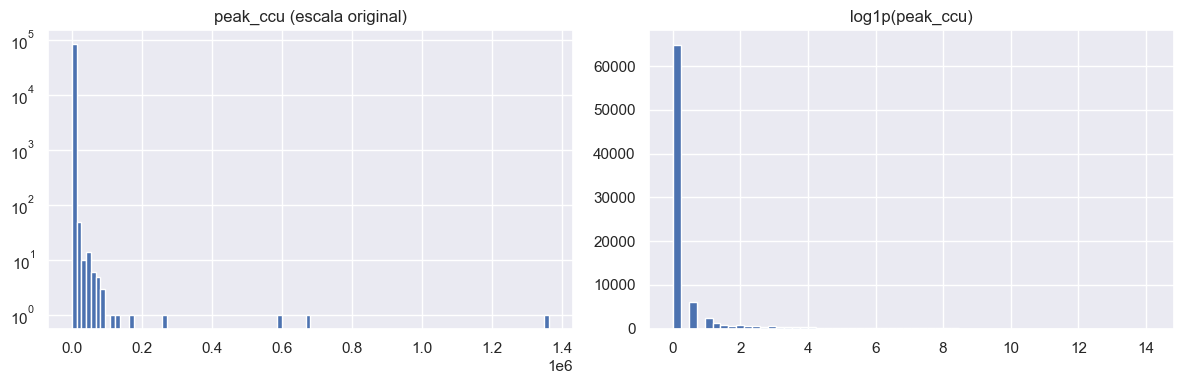

In [25]:


fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(p, bins=100); ax[0].set_title("peak_ccu (escala original)"); ax[0].set_yscale("log")
ax[1].hist(np.log1p(p), bins=60); ax[1].set_title("log1p(peak_ccu)")
plt.tight_layout(); plt.show()

A distribuição é extremamente assimétrica: a mediana é 0 e poucos jogos passam de milhares de jogadores. Regressão no valor bruto seria dominada por poucos outliers.
Por isso o alvo da modelagem será uma **classificação em faixas**, com regressão em `log1p(peak_ccu)` como análise complementar.

           jogos     %
faixa_ccu             
0          64966  77.7
1-20       14438  17.3
21-500      3435   4.1
500+         807   1.0


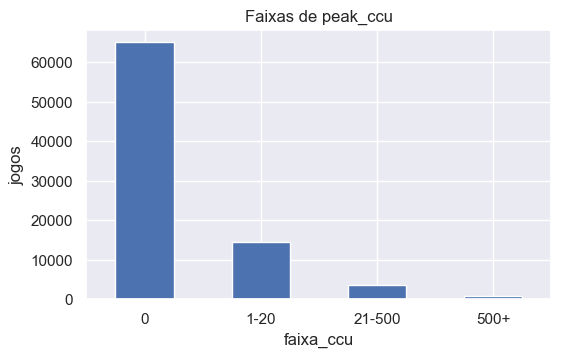

In [26]:
bins = [-1,0,20,500,np.inf]
labels = ["0", "1-20", "21-500", "500+"]
dataset["faixa_ccu"] = pd.cut(dataset.peak_ccu, bins=bins, labels=labels)
dataset["log_ccu"] = np.log1p(dataset.peak_ccu)
cont = dataset.faixa_ccu.value_counts().reindex(labels)
print(pd.DataFrame({"jogos": cont, "%": (cont / len(dataset) * 100).round(1)}))
ax = cont.plot(kind="bar", figsize=(6, 3.5), rot=0); ax.set_ylabel("jogos"); ax.set_title("Faixas de peak_ccu")
plt.show()





As classes são muito desbalanceadas (`0` domina e `500+` é cerca de 1%). Na modelagem: split estratificado, `class_weight` e F1-macro como métrica principal (acurácia sozinha seria enganosa).